# Real estate portfolio screening with Cotality and CARTO MCPs

**SDSC 2026 workshop · follow-along notebook**

You manage a portfolio of about 1,000 properties in south Lee County, Florida, and the address list is messy.
In Section 1 you clean it up and add climate risk, using the results of the same Cotality MCP calls the
presenters run live. In Section 2 you load the data into CARTO and ask a map's AI agent where your
properties sit relative to new growth and climate risk.

| Part | What you do |
|---|---|
| 0 · Setup | Install anything missing and find the data |
| 1 · Profile | How messy is the address list? |
| 2 · Resolve | Every row to a Cotality property ID (CLIP); duplicates collapse |
| 3 · Climate risk | Property-level climate risk for every CLIP: **checkpoint 1** |
| 4 · Into CARTO | Upload the data (browser or Claude), set up the map's AI agent, ask questions |

**Reference docs in this repo**

- [README](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening#readme): workshop overview and setup
- [DATA.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/DATA.md): every file and column
- [maps/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/README.md): build the map in CARTO
- [maps/agent_instructions.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/agent_instructions.md): the agent's Use Case and Instructions
- [maps/prompts.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/prompts.md): questions to ask, with expected answers
- [semantic_models/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/semantic_models/README.md): the agent's semantic model
- [mcp/carto_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/carto_on_claude.md): connect the CARTO MCP server to Claude
- [mcp/cotality_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/cotality_on_claude.md): connect the Cotality MCP server to Claude

Run the cells top to bottom (**Shift + Enter**). Each finishes in a few seconds.

## 0 · Setup

**Where are you running this?**

- **A clone of this repo:** set up the environment once with `pip install -r requirements.txt` (see the
  README). The notebook reads the files in the repo's `data/` folder.
- **Google Colab, with the code pasted in:** pandas, GeoPandas, PyArrow and Matplotlib are already
  installed. The cell below installs anything missing, and the next one downloads the data files into your
  Colab session. Colab deletes them when the session ends: if you come back later, run the cells from the
  top again.

In [1]:
import importlib.util
import subprocess
import sys

for package in ("pandas", "geopandas", "pyarrow", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        print(f"installing {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
print("packages ready")

packages ready


In [2]:
import os
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

GITHUB_REPO = "eprashar-clgx/sdsc-2026-re-portfolio-screening"
REPO_URL = os.environ.get("PORTFOLIO_REPO_URL", f"https://raw.githubusercontent.com/{GITHUB_REPO}/main/")
FILES = ["portfolio_messy.csv", "portfolio_truth.csv", "portfolio_matches.parquet", "portfolio_risk.parquet",
         "growth_h3_r9.parquet", "growth_parcels.parquet", "parcel_essentials.parquet"]


def find_data():
    """Use data/ from a clone of the repo if there is one; otherwise download the files from GitHub."""
    for folder in (Path("data"), Path("../data")):
        if all((folder / f).exists() for f in FILES):
            print(f"using the data in {folder}/")
            return folder
    folder = Path("data")
    folder.mkdir(exist_ok=True)
    for f in FILES:
        if not (folder / f).exists():
            print(f"downloading {f} ...")
            urllib.request.urlretrieve(REPO_URL + "data/" + f, folder / f)
    print(f"data saved in {folder}/")
    return folder


DATA = find_data()
pd.set_option("display.max_colwidth", 70)

using the data in ../data/


## 1 · Profile: how messy is the list?

`portfolio_messy.csv` is the list as you'd receive it: one address per row, typed by different people over
the years. How far do a few rules of thumb get you?

In [3]:
messy = pd.read_csv(DATA / "portfolio_messy.csv")
print(f"{len(messy):,} rows")
messy.sample(8, random_state=4)

1,130 rows


,input_id,address
88,89,"27351 Poinciana Drive, Bonita Springs, FL 34135"
650,651,"27507 Baretta Drive, Bonita Springs, FL 34135"
956,957,"12070 Matera Ln #204, Bonita Springs, FL 34135"
804,805,"9950/9952 Carolina St, Bonita Springs, FL 34135"
1076,1077,"9708 Strike Lane, Bonita Springs, FL 34135"
138,139,"27307 High Seas Ln, Bonita Springs, FL 34135"
411,412,"10085 Maddox Ln, Bonita Springs, FL"
447,448,"9423 Oak Strand Dr, Estero, FL 34135"


In [4]:
address = messy["address"]
normalized = (address.str.lower()
              .str.replace(r"[^a-z0-9 ]", " ", regex=True)
              .str.replace(r"\b\d{5}\b\s*$", "", regex=True)
              .str.replace(r"\s+", " ", regex=True).str.strip())
flags = pd.DataFrame({
    "no ZIP code": ~address.str.contains(r"\b\d{5}\.?\s*$"),
    "case, spacing or punctuation": (address.ne(address.str.strip()) | address.str.contains("  ")
                                     | address.eq(address.str.lower()) | ~address.str.contains(",")
                                     | address.str.contains(r"\.")),
    "no house number": ~address.str.strip().str.match(r"^\d"),
    "same text as another row": normalized.duplicated(keep=False),
})
summary = flags.sum().sort_values(ascending=False).rename("rows flagged").to_frame()
summary["share"] = (summary["rows flagged"] / len(messy)).map("{:.0%}".format)
print(f"rows with at least one flag: {flags.any(axis=1).mean():.0%}")
summary

rows with at least one flag: 20%


,rows flagged,share
"case, spacing or punctuation",121,11%
no ZIP code,93,8%
same text as another row,37,3%
no house number,20,2%


The rules flag about one row in five. They catch formatting problems and missing ZIP codes, but miss typos,
abbreviations, wrong cities and most duplicates, which are typed differently each time. The answer key,
`portfolio_truth.csv`, shows what was actually done to each row: nearly two thirds have a problem.

In [5]:
truth = pd.read_csv(DATA / "portfolio_truth.csv", dtype={"truth_clip": str})
mix = truth["error_type"].value_counts().rename("rows").to_frame()
mix["share"] = (mix["rows"] / len(truth)).map("{:.0%}".format)
print(f"rows with an error: {(truth['error_type'] != 'clean').mean():.0%}    "
      f"duplicate rows: {truth['is_duplicate'].sum()}    rows with no real property: "
      f"{(truth['error_type'] == 'unmatchable').sum()}")
mix

rows with an error: 63%    duplicate rows: 100    rows with no real property: 30


,rows,share
error_type,,
clean,414,37%
abbreviation,171,15%
typo,116,10%
zip,115,10%
case_punct,114,10%
unit,103,9%
wrong_city,67,6%
unmatchable,30,3%


## 2 · Resolve: one messy address in, one CLIP out

The presenters send addresses to the Cotality MCP tool `clip-find_property_by_address`, which returns the
property's **CLIP** (Cotality's persistent property ID), a standardized address and a location.
`portfolio_matches.parquet` holds the result of that call for every row. Compare it with the answer key:

In [6]:
matches = gpd.read_parquet(DATA / "portfolio_matches.parquet")
scored = matches.merge(truth[["input_id", "error_type", "is_duplicate", "truth_clip"]], on="input_id")
scored["outcome"] = "correct CLIP"
scored.loc[scored["match_status"] != "matched", "outcome"] = "not found"
scored.loc[(scored["match_status"] == "matched") & (scored["clip"] != scored["truth_clip"]), "outcome"] = "wrong CLIP"

by_type = pd.crosstab(scored["error_type"], scored["outcome"], margins=True, margins_name="all rows")
by_type["% correct"] = (100 * by_type["correct CLIP"] / by_type["all rows"]).round(0)
pd.concat([by_type.drop(index="all rows").sort_values("% correct"), by_type.loc[["all rows"]]])

outcome,correct CLIP,not found,wrong CLIP,all rows,% correct
error_type,,,,,
unmatchable,0,30,0,30,0.0
unit,43,58,2,103,42.0
typo,88,28,0,116,76.0
abbreviation,170,0,1,171,99.0
wrong_city,66,1,0,67,99.0
clean,410,3,1,414,99.0
case_punct,114,0,0,114,100.0
zip,115,0,0,115,100.0
all rows,1006,120,4,1130,89.0


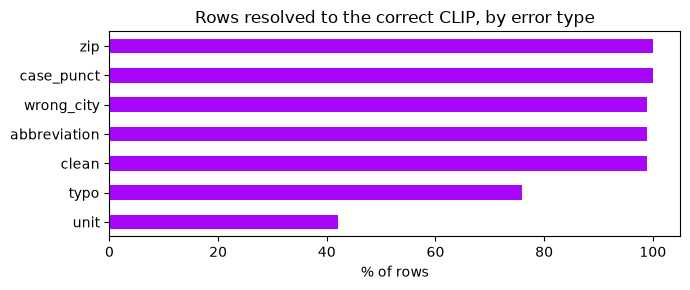

In [7]:
rates = by_type.drop(index="all rows")["% correct"].drop(index="unmatchable").sort_values()
ax = rates.plot.barh(figsize=(7, 3), color="#a805fb", title="Rows resolved to the correct CLIP, by error type")
ax.set_xlabel("% of rows"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Formatting, abbreviations, a missing ZIP or a wrong city barely matter: the address lookup fixes them.
Typos fail about one time in four, and **a dropped unit number always fails**: in a condo building the
street address alone doesn't identify a property. All 30 fake addresses come back "not found", with no
false matches.

Duplicates collapse on their own once every row has a CLIP:

In [8]:
matched = scored[scored["match_status"] == "matched"]
print(f"{len(scored):,} rows  ->  {len(matched):,} matched  ->  {matched['clip'].nunique():,} unique properties (CLIPs)")
dupes = scored[scored["is_duplicate"]]
print(f"duplicate rows resolved to the right property: {(dupes['outcome'] == 'correct CLIP').sum()} of {len(dupes)}")

1,130 rows  ->  1,010 matched  ->  929 unique properties (CLIPs)
duplicate rows resolved to the right property: 96 of 100


## 3 · Climate risk: checkpoint 1

Next, the presenters call the Cotality MCP tool `at-get_property_climate_risk` for each CLIP. It returns
scores for 12 perils, today and in 2030, 2040 and 2050 under four emissions scenarios. Scores run from 1 to
100 (higher is riskier) and rank a property against others of the same type.

`portfolio_risk.parquet` is the result: one row per property with its CLIP, location, H3 cell and the key
scores. **This is checkpoint 1**, the table you load into CARTO in part 4.

In [9]:
risk = gpd.read_parquet(DATA / "portfolio_risk.parquet")
print(f"{len(risk):,} properties, {risk['risk_score'].notna().sum():,} with climate risk scores")
risk[["clip", "resolved_address", "risk_score", "cfl_score", "tcwi_score", "call_score_ssp5_85_2050"]].head()

929 properties, 926 with climate risk scores


,clip,resolved_address,risk_score,cfl_score,tcwi_score,call_score_ssp5_85_2050
0,3935990992,25250 STILLWELL PKWY BONITA SPRINGS FL 34135-8851,67.0,54.0,77.0,78.0
1,6106822015,26931 SAMMOSET WAY BONITA SPRINGS FL 34135-6584,82.0,75.0,84.0,89.0
2,7972192512,28710 DIAMOND DR UNIT 205 BONITA SPRINGS FL 34134-1338,69.0,69.0,77.0,81.0
3,1097836956,8635 RIVER HOMES LN # 2102 BONITA SPRINGS FL 34135-4368,76.0,80.0,77.0,87.0
4,4905002271,25252 CORDERA POINT DR BONITA SPRINGS FL 34135-5389,14.0,55.0,46.0,30.0


In [10]:
perils = {"call_score": "All perils", "tcwi_score": "Hurricane wind", "cfl_score": "Flood (inland + surge)",
          "flxx_score": "Inland flood", "tcfl_score": "Storm surge", "ceq_score": "Earthquake",
          "call_score_ssp5_85_2050": "All perils, 2050 (high emissions)"}
risk[list(perils)].rename(columns=perils).describe().loc[["mean", "25%", "50%", "75%"]].round(0).T

,mean,25%,50%,75%
All perils,55.0,36.0,59.0,74.0
Hurricane wind,68.0,54.0,71.0,77.0
Flood (inland + surge),64.0,52.0,67.0,75.0
Inland flood,49.0,27.0,55.0,66.0
Storm surge,29.0,18.0,25.0,40.0
Earthquake,7.0,5.0,7.0,7.0
"All perils, 2050 (high emissions)",68.0,54.0,73.0,84.0


Hurricane wind and flood drive most of the risk here, and the all-perils score rises by about 14 points by
2050 under high emissions. The map shows where the riskier properties are:

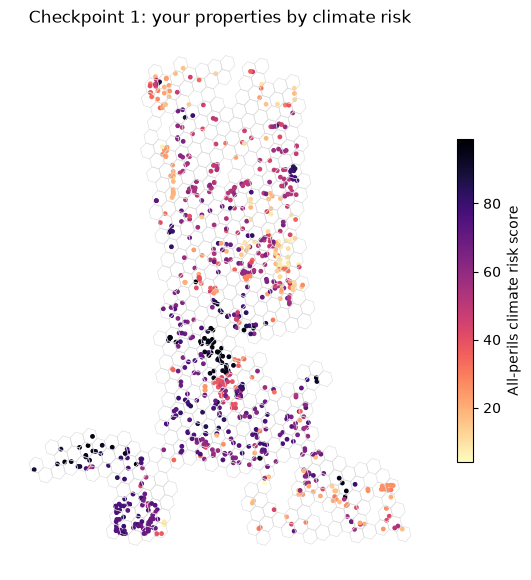

In [11]:
cells = gpd.read_parquet(DATA / "growth_h3_r9.parquet")
fig, ax = plt.subplots(figsize=(7, 7))
cells.boundary.plot(ax=ax, color="#d9d9d9", linewidth=0.4)
risk.plot(ax=ax, column="risk_score", cmap="magma_r", markersize=6, legend=True,
          legend_kwds={"label": "All-perils climate risk score", "shrink": 0.6})
ax.set_title("Checkpoint 1: your properties by climate risk"); ax.set_axis_off()
plt.show()

## 4 · Into CARTO

Section 2 happens in CARTO Builder. You need four files from this repo's `data/` folder:

| File | What it is |
|---|---|
| `portfolio_risk.parquet` | Checkpoint 1: your 929 properties with climate risk |
| `growth_h3_r9.parquet` | 459 H3 cells with growth and risk measures |
| `growth_parcels.parquet` | 918 properties where new development is happening |
| `parcel_essentials.parquet` | Every parcel in the study area (about 12 MB) |

Load them with either option below, keeping each table's name the same as its file name
(`portfolio_risk`, `growth_h3_r9`, `growth_parcels`, `parcel_essentials`) and all four in the same dataset.

### Option A · In the browser

1. Download the four files: from your clone's `data/` folder, from this repo's `data/` folder on GitHub,
   or (in Colab) from the **Files** panel on the left.
2. In CARTO Workspace, open **Data Explorer** and click **Import data**.
3. Choose a file, then pick the **CARTO Data Warehouse** connection and your **private** dataset. Keep the
   suggested table name if it matches the file name; otherwise type it (for example `portfolio_risk`).
4. Repeat for the other three files.
5. Open one of the new tables and note its full name, shown at the top: `carto-dw-ac-xxxx.private_yourname_xxxx.portfolio_risk`.
   The part before the last dot is your **project and dataset**; you need it for the semantic model below.

### Option B · In Claude, with the CARTO MCP server

1. Connect the CARTO MCP server to Claude: see
   [mcp/carto_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/carto_on_claude.md).
2. Ask Claude to import the files from their URLs (the next cell prints them), for example:
   *"Import these four files into my CARTO Data Warehouse private dataset, naming each table after its file
   name, and tell me the full table names."*

The CARTO MCP server's import tool loads files from a URL, so this option works once you have the URLs below.

In [12]:
for f in ("portfolio_risk.parquet", "growth_h3_r9.parquet", "growth_parcels.parquet", "parcel_essentials.parquet"):
    print(REPO_URL + "data/" + f)

https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/portfolio_risk.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/growth_h3_r9.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/growth_parcels.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/parcel_essentials.parquet


### Set up the map and its AI agent

1. In Builder, create a map and add the tables as layers: `growth_h3_r9` (cells), `growth_parcels`, and
   `portfolio_risk` on top. `parcel_essentials` is optional on the map; the agent can query it either way.
2. Add an **AI agent** to the map and fill in:
   - **Use Case** and **Instructions**: copy them from
     [maps/agent_instructions.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/agent_instructions.md).
   - **Semantic model**: the file `semantic_models/portfolio_screening.yaml` with your project and dataset
     filled in. Set `MY_DATASET` in the next cell and run it: it writes the file for you (and in Colab,
     downloads it). Then import that file in the agent's semantic model settings.
   - **Capabilities**: turn on **Query sources** so the agent can run SQL.

   More detail: [maps/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/README.md)
   and [semantic_models/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/semantic_models/README.md).

In [13]:
MY_DATASET = "YOUR_PROJECT.YOUR_DATASET"  # e.g. "carto-dw-ac-abcd1234.private_jane_1a2b3c4d"

PLACEHOLDER = "YOUR_PROJECT.YOUR_DATASET"
source = Path("semantic_models/portfolio_screening.yaml")
if not source.exists():
    source = Path("../semantic_models/portfolio_screening.yaml")
if source.exists():
    model = source.read_text()
else:
    with urllib.request.urlopen(REPO_URL + "semantic_models/portfolio_screening.yaml") as response:
        model = response.read().decode()

if MY_DATASET == PLACEHOLDER:
    print("Set MY_DATASET above to your project and dataset, then run this cell again.")
else:
    out = Path("portfolio_screening_semantic_model.yaml")
    out.write_text(model.replace(PLACEHOLDER, MY_DATASET.strip().strip("`")))
    print(f"wrote {out} ({model.count(PLACEHOLDER)} table references set to {MY_DATASET})")
    try:
        from google.colab import files
        files.download(str(out))
    except ImportError:
        pass

Set MY_DATASET above to your project and dataset, then run this cell again.


### Ask the agent

Ask these in order. The expected answers come from the same data, so your agent should match them.
[maps/prompts.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/prompts.md) has more to try.

| Prompt | Expected answer |
|---|---|
| Which of my properties sit in high-growth cells? | 473 of 929 (238 Pursue, 235 Watchlist) |
| Classify the cells into Pursue, Watchlist, Hold and Reassess, and colour the map by quadrant. | Pursue 62 cells, Watchlist 158, Hold 158, Reassess 77, Unclassified 4 |
| For each quadrant, show the number of cells, my properties and growth parcels, the average growth parcels per cell, and the mix of growth stages. | Watchlist: 158 cells, 235 properties, 608 growth parcels |
| Which Watchlist properties have a lower property-level climate risk than their cell? | 47 of the 235 |

**Want to redo the live Cotality steps yourself?** Connect the Cotality MCP server to Claude:
[mcp/cotality_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/cotality_on_claude.md).